# BANKING77: output control and reasoning

Two questions on top of the scaling experiment (`01_banking77_qwen_scaling.ipynb`):

1. **Structured vs. open answers.** How much does it matter that we *force* the model to emit a valid label?
2. **Reasoning.** Does letting a small model think before answering improve accuracy, and what does it cost?

Results are cached under `results/banking77/<mode>_<think|no-think>/`; the same runs are available as
`scripts/run_banking77.py --mode ... [--think]`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from slm import RESULTS_DIR
from slm.data import load_banking77
from slm.evaluation import OUTPUT_MODES, LLMClassifier, evaluate, score, stratified_subset
from slm.evaluation.classification import ANSWER_FORMATS, INVALID
from slm.inference import THINKING_OPTIONS, OllamaBackend, params_in_billions

pd.set_option("display.max_colwidth", 200)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order
RESULTS = RESULTS_DIR / "banking77"
dataset = load_banking77()


def run(model, mode="structured", think=False, data=None, workers=4):
    """Evaluate one configuration (cached) and return per-example results."""
    backend = OllamaBackend(model, think=think, **(THINKING_OPTIONS if think else {}))
    cache = RESULTS / f"{mode}_{'think' if think else 'no-think'}" / f"{model.replace(':', '_')}.jsonl"
    return evaluate(LLMClassifier(backend, dataset.labels, mode=mode), data, cache_file=cache, workers=workers)


def style(ax, title):
    ax.set_title(title, loc="left")
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

/home/phth01/PycharmProjects/small-language-models/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1: Structured vs. open answers

Three levels of output control, with the same prompt except for the last line:

| mode | what Ollama enforces | answer instruction |
|---|---|---|
| `structured` | JSON schema with an `enum` of the 77 labels (constrained decoding) | JSON object |
| `json` | syntactically valid JSON, any content | JSON object |
| `free` | nothing | intent name only |

Free answers are scored twice: **strict** (the answer must be exactly a label) and **lenient**
(case, quotes, spaces vs. underscores, small typos and labels embedded in a sentence are forgiven).

In [2]:
for mode in OUTPUT_MODES:
    print(f"{mode:>10}: {ANSWER_FORMATS[mode]}")

structured: Answer with a JSON object of the form {"label": "<intent>"}.
      json: Answer with a JSON object of the form {"label": "<intent>"}.
      free: Answer with the name of the intent only, exactly as written in the list above.


In [3]:
MODELS = ["qwen3.5:0.8b", "qwen3.5:2b", "qwen3.5:4b", "qwen3.5:9b"]
subset = stratified_subset(dataset.test, per_class=10)  # 770 queries

outputs, rows = {}, []
for mode in OUTPUT_MODES:
    for model in MODELS:
        outputs[mode, model] = res = run(model, mode, data=subset)
        rows.append({"mode": mode, "model": model, "params_b": params_in_billions(model), **score(res)})
modes = pd.DataFrame(rows)
modes.pivot(index="model", columns="mode", values=["accuracy", "accuracy_lenient", "invalid_rate"]).round(3)

qwen3.5:0.8b: 0it [00:00, ?it/s]

qwen3.5:0.8b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

...

qwen3.5:4b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

qwen3.5:9b: 0it [00:00, ?it/s]

qwen3.5:9b: 0it [00:00, ?it/s]

accuracy                   accuracy_lenient                    \
mode             free   json structured             free   json structured   
model                                                                        
qwen3.5:0.8b    0.456  0.338      0.449            0.462  0.342      0.449   
qwen3.5:2b      0.516  0.496      0.500            0.521  0.503      0.500   
qwen3.5:4b      0.651  0.658      0.656            0.653  0.666      0.656   
qwen3.5:9b      0.694  0.694      0.696            0.696  0.704      0.696   

             invalid_rate                    
mode                 free   json structured  
model                                        
qwen3.5:0.8b        0.026  0.232        0.0  
qwen3.5:2b          0.016  0.023        0.0  
qwen3.5:4b          0.005  0.012        0.0  
qwen3.5:9b          0.004  0.017        0.0

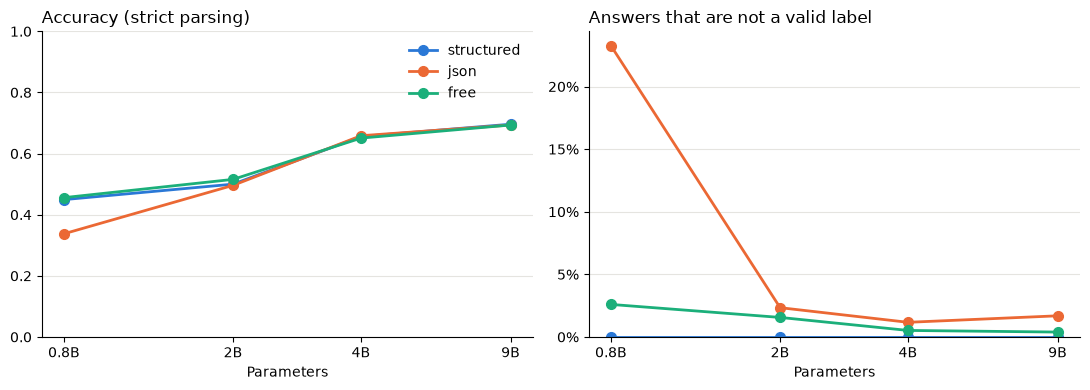

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for color, mode in zip(COLORS, OUTPUT_MODES):
    grp = modes[modes["mode"] == mode].sort_values("params_b")
    axes[0].plot(grp["params_b"], grp["accuracy"], marker="o", markersize=7, linewidth=2, color=color, label=mode)
    axes[1].plot(grp["params_b"], grp["invalid_rate"], marker="o", markersize=7, linewidth=2, color=color, label=mode)
for ax, title in zip(axes, ["Accuracy (strict parsing)", "Answers that are not a valid label"]):
    ax.set_xscale("log")
    ax.set_xticks(modes["params_b"].unique(), [f"{p:g}B" for p in modes["params_b"].unique()])
    ax.minorticks_off()
    ax.set_xlabel("Parameters")
    style(ax, title)
axes[0].set_ylim(0, 1)
axes[1].set_ylim(bottom=0)
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].legend(frameon=False)
fig.tight_layout()

### What do invalid answers look like?

Typical failure modes of unconstrained output: invented labels, paraphrases, extra words.
Lenient parsing recovers some of them, at the price of hand-written matching rules.

In [5]:
res = pd.concat({model: outputs["free", model] for model in MODELS}, names=["model"])
invalid = res[res["prediction"] == INVALID]
invalid[["text", "label", "raw", "prediction_lenient"]].groupby(level="model").head(4)

text  \
model                                                                                    
qwen3.5:0.8b 370                               How can I get my physical card to work?   
             498   Do you offer services for children to have money saving experience?   
             1363                How do I make more than one disposable card in a day?   
             1364                            Can I have more than one disposable card?   
qwen3.5:2b   41                                    I would like to reactivate my card.   
             673                                 Where is the money I topped off with?   
             1335                         How do I transfer money using a credit card?   
             1343                            Help me transfer money to my credit card.   
qwen3.5:4b   1636                                What does a pending transaction mean?   
             2095                        Do you know why my card payment was reverted?   
             2505                            What are the fees to get a physical card?   
             2623           What is the process of obtaining a disposable virtual card   
qwen3.5:9b   1265                                      Where is my PIN number located?   
             1335                         How do I transfer money using a credit card?   
             1340              Is there a way to transfer funds directly from my card?   

                                         label  \
model                                            
qwen3.5:0.8b 370              card_not_working   
             498                     age_limit   
             1363       disposable_card_limits   
             1364       disposable_card_limits   
qwen3.5:2b   41                   card_linking   
             673                pending_top_up   
             1335           topping_up_by_card   
             1343           topping_up_by_card   
qwen3.5:4b   1636         pending_card_payment   
             2095       reverted_card_payment?   
             2505          order_physical_card   
             2623  get_disposable_virtual_card   
qwen3.5:9b   1265            get_physical_card   
             1335           topping_up_by_card   
             1340           topping_up_by_card   

                                               raw  \
model                                                
qwen3.5:0.8b 370             getting_physical_card   
             498                                no   
             1363  getting_disposable_virtual_card   
             1364                              yes   
qwen3.5:2b   41            reactivate_card_payment   
             673                    top_up_by_card   
             1335                   top_up_by_card   
             1343                   top_up_by_card   
qwen3.5:4b   1636              pending_transaction   
             2095            reverted_card_payment   
             2505            getting_physical_card   
             2623  getting_disposable_virtual_card   
qwen3.5:9b   1265                     where_is_pin   
             1335                   top_up_by_card   
             1340                   top_up_by_card   

                            prediction_lenient  
model                                           
qwen3.5:0.8b 370             get_physical_card  
             498                     <invalid>  
             1363  get_disposable_virtual_card  
             1364                    <invalid>  
qwen3.5:2b   41         reverted_card_payment?  
             673            topping_up_by_card  
             1335           topping_up_by_card  
             1343           topping_up_by_card  
qwen3.5:4b   1636                    <invalid>  
             2095       reverted_card_payment?  
             2505            get_physical_card  
             2623  get_disposable_virtual_card  
qwen3.5:9b   1265                    <invalid>  
             1335           topping_up_by_card

In [6]:
# Invented labels: answers that are not a label even after lenient matching
invented = invalid[invalid["prediction_lenient"] == INVALID]
invented.groupby(level="model")["raw"].agg(lambda s: s.str.strip().value_counts().head(5).to_dict())

model
qwen3.5:0.8b    {'yes': 2, 'no': 1, 'get_top_up_verification_code': 1}
qwen3.5:2b                                  {'salary_not_received': 1}
qwen3.5:4b                                  {'pending_transaction': 1}
qwen3.5:9b                                         {'where_is_pin': 1}
Name: raw, dtype: object

## Part 2: Reasoning (thinking mode)

Qwen3.5 models can produce a reasoning trace before the answer (`think=True`). We compare a small and a
medium model with and without thinking on a balanced subset (5 queries per intent), keeping the
structured output. Thinking runs sample with temperature 0.6, top-p 0.95, top-k 20 (plus Ollama's default
presence penalty of 1.5 for Qwen3.5), because greedy decoding tends to get stuck in loops while reasoning.
This sits between the model card's settings for general (temperature 1.0) and precise tasks
(presence penalty 0). The reasoning trace is capped at 4,096 tokens: **a capped trace has no answer**.

In [7]:
THINK_MODELS = ["qwen3.5:2b", "qwen3.5:4b"]
subset = stratified_subset(dataset.test, per_class=5)  # 385 queries

reasoning, rows = {}, []
for model in THINK_MODELS:
    for think in (False, True):
        reasoning[model, think] = res = run(model, think=think, data=subset)
        rows.append({"model": model, "think": think, **score(res)})
think_summary = pd.DataFrame(rows)
think_summary[["model", "think", "accuracy", "mean_completion_tokens", "mean_latency_s", "truncated_rate"]].round(3)

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

,model,think,accuracy,mean_completion_tokens,mean_latency_s,truncated_rate
0,qwen3.5:2b,False,0.488,12.119,1.242,NaN
1,qwen3.5:2b,True,0.457,2653.730,164.525,0.40
2,qwen3.5:4b,False,0.668,9.844,2.514,NaN
3,qwen3.5:4b,True,0.564,2576.735,310.484,0.33


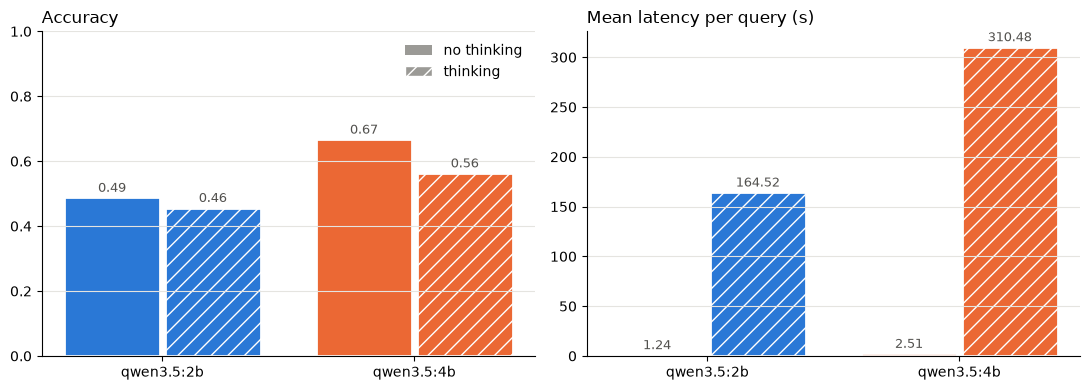

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "mean_latency_s", "Mean latency per query (s)")]:
    for i, (color, model) in enumerate(zip(COLORS, THINK_MODELS)):
        grp = think_summary[think_summary["model"] == model]
        bars = ax.bar([i - 0.2, i + 0.2], grp[col], width=0.38, color=color, edgecolor="white", linewidth=2)
        bars[1].set_hatch("//")  # thinking
        for bar, value in zip(bars, grp[col]):
            ax.annotate(f"{value:.2f}", (bar.get_x() + bar.get_width() / 2, value), textcoords="offset points",
                        xytext=(0, 4), ha="center", fontsize=9, color="#52514e")
    ax.set_xticks(range(len(THINK_MODELS)), THINK_MODELS)
    style(ax, title)
axes[0].set_ylim(0, 1)
axes[0].legend(handles=[Patch(facecolor="#9b9a96", label="no thinking"),
                        Patch(facecolor="#9b9a96", hatch="//", edgecolor="white", label="thinking")], frameon=False)
fig.tight_layout()

### Which answers change?

Thinking does not only fix errors, it also breaks answers that were right before.

In [9]:
for model in THINK_MODELS:
    before = reasoning[model, False]["prediction"] == subset["label"]
    after = reasoning[model, True]["prediction"] == subset["label"]
    print(model)
    print(pd.crosstab(before.rename("correct without thinking"), after.rename("correct with thinking")), "\n")

qwen3.5:2b
correct with thinking     False  True 
correct without thinking              
False                       164     33
True                         45    143 

qwen3.5:4b
correct with thinking     False  True 
correct without thinking              
False                       112     16
True                         56    201 



In [10]:
model = THINK_MODELS[0]
plain, thought = reasoning[model, False], reasoning[model, True]
fixed = thought[(plain["prediction"] != subset["label"]) & (thought["prediction"] == subset["label"])]
example = fixed.iloc[0]
print(f"query:    {example.text}\ngold:     {example.label}\nwithout:  {plain.loc[example.name, 'prediction']}\n")
print(f"reasoning ({example.completion_tokens} tokens):\n{example.thinking}")

query:    When will I get my card?
gold:     card_arrival
without:  card_delivery_estimate

reasoning (3422 tokens):
Thinking Process:

1.  **Analyze the Request:**
    *   Task: Intent classification for customer messages sent to a bank.
    *   Input Message: "When will I get my card?"
    *   Output Format: JSON object `{"label": "<intent>"}`.
    *   Allowed Intents: A specific list of 50+ intents provided in the prompt.

2.  **Analyze the Input Message:**
    *   Message: "When will I get my card?"
    *   Key Information: The user is asking about the delivery time or arrival date of their physical bank card.
    *   Match with Allowed Intents:
        *   `card_arrival`: Matches "When will I get my card?" (asking about arrival).
        *   `getting_virtual_card`: Usually asks for activation, not specifically the date of a physical card, though related. However, `card_arrival` is more specific to delivery time.
        *   `get_physical_card`: Asks for a card, but usually implies

## Part 3: How much thinking is worth it? Budget forcing and extension

Two interventions on the reasoning traces from Part 2 (`scripts/run_thinking_budget.py`):

* **Budget forcing**: cut every trace after *b* tokens, append *"Considering the limited time by the user, I have
  to give the solution based on the thinking directly now."* and close the thinking block, so the model must
  answer immediately. Traces that end within the budget keep their natural answer.
* **Extension**: traces that hit the 4,096-token limit are continued by up to 4,096 more tokens (8k total).

Both need the raw prompt, so we send Qwen's chat template ourselves (`raw=True` in Ollama); token positions
are exact thanks to the original Qwen tokenizer. Budget 0 is the run without thinking.

In [11]:
BUDGET_DIR = RESULTS / "thinking_budget"
budgets = pd.read_csv(BUDGET_DIR / "summary_5pc.csv")
budgets.pivot(index="budget", columns="model", values=["accuracy", "mean_thinking_tokens", "forced_rate"]).round(3)

accuracy            mean_thinking_tokens            forced_rate  \
model  qwen3.5:2b qwen3.5:4b           qwen3.5:2b qwen3.5:4b  qwen3.5:2b   
budget                                                                     
0           0.488      0.668                0.000      0.000       0.000   
256         0.494      0.639              254.060    256.000       0.971   
512         0.530      0.631              495.312    505.836       0.891   
1024        0.553      0.668              909.195    957.719       0.743   
2048        0.590      0.696             1596.821   1649.457       0.616   
3072        0.569      0.691             2168.917   2161.268       0.512   
4096        0.584      0.691             2644.743   2566.979       0.400   
6144        0.574      0.691             3217.379   3086.075       0.184   
8192        0.574      0.688             3479.135   3294.434       0.083   

                   
model  qwen3.5:4b  
budget             
0           0.000  
256         1.000  
512         0.922  
1024        0.847  
2048        0.548  
3072        0.455  
4096        0.330  
6144        0.177  
8192        0.062

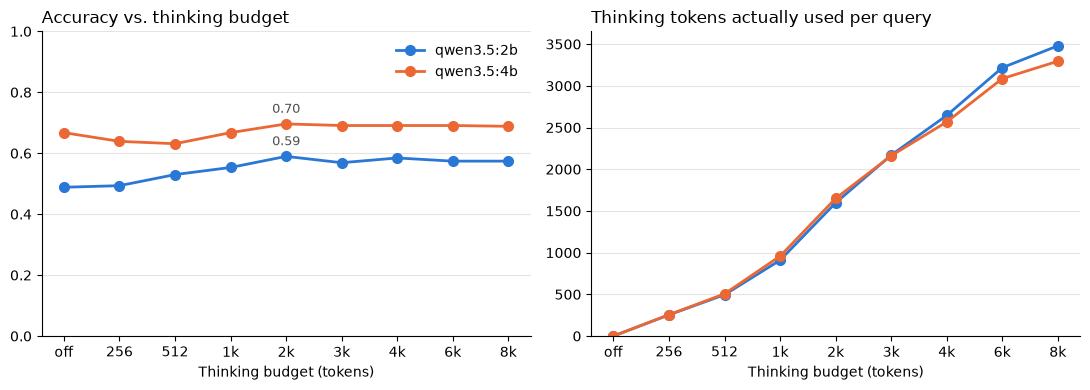

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
levels = sorted(budgets["budget"].unique())
ticks = ["off" if b == 0 else (f"{b // 1024}k" if b >= 1024 else str(b)) for b in levels]
for color, (model, grp) in zip(COLORS, budgets.groupby("model")):
    x = [levels.index(b) for b in grp["budget"]]
    axes[0].plot(x, grp["accuracy"], marker="o", markersize=7, linewidth=2, color=color, label=model)
    axes[1].plot(x, grp["mean_thinking_tokens"], marker="o", markersize=7, linewidth=2, color=color, label=model)
    best = grp.loc[grp["accuracy"].idxmax()]
    axes[0].annotate(f"{best['accuracy']:.2f}", (levels.index(best["budget"]), best["accuracy"]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color="#52514e")
for ax, title in zip(axes, ["Accuracy vs. thinking budget", "Thinking tokens actually used per query"]):
    ax.set_xticks(range(len(levels)), ticks)
    ax.set_xlabel("Thinking budget (tokens)")
    style(ax, title)
axes[0].set_ylim(0, 1)
axes[1].set_ylim(bottom=0)
axes[0].legend(frameon=False)
fig.tight_layout()

### Does more room help? The traces that hit the 4,096-token limit

We split the queries by when their reasoning ends: within 4k tokens, between 4k and 8k (only thanks to the
extension), or not even within 8k. For late traces we compare the natural answer with the answer forced at 4k.

In [13]:
def load_jsonl(path):
    df = pd.read_json(path, lines=True)
    return df.assign(idx=df["key"].astype(str).str.split("@").str[0].astype(int))

rows = []
for model in THINK_MODELS:
    name = model.replace(":", "_")
    label = subset["label"]
    plain, thought = reasoning[model, False]["prediction"], reasoning[model, True]
    ext = load_jsonl(BUDGET_DIR / f"{name}_extension.jsonl").set_index("idx")
    late = load_jsonl(BUDGET_DIR / f"{name}_late_answers.jsonl").set_index("idx")["prediction"]
    forced = load_jsonl(BUDGET_DIR / f"{name}_forced.jsonl")
    forced["budget"] = forced["key"].str.split("@").str[1].astype(int)
    at = lambda b: forced[forced["budget"] == b].set_index("idx")["prediction"]
    early = thought.index[thought["done_reason"] == "stop"]
    never = ext.index[~ext["finished"]]
    acc = lambda pred, idx: (pred.loc[idx] == label.loc[idx]).mean()
    rows += [
        {"model": model, "trace ends": "within 4k", "n": len(early),
         "natural answer": acc(thought["prediction"], early), "no thinking": acc(plain, early)},
        {"model": model, "trace ends": "4k-8k", "n": len(late), "natural answer": acc(late, late.index),
         "forced at 4k": acc(at(4096), late.index), "no thinking": acc(plain, late.index)},
        {"model": model, "trace ends": "never (>8k)", "n": len(never), "forced at 4k": acc(at(4096), never),
         "forced at 8k": acc(at(8192), never), "no thinking": acc(plain, never)},
    ]
pd.DataFrame(rows).round(3)

,model,trace ends,n,natural answer,no thinking,forced at 4k,forced at 8k
0,qwen3.5:2b,within 4k,231,0.762,0.641,NaN,NaN
1,qwen3.5:2b,4k-8k,122,0.336,0.262,0.336,NaN
2,qwen3.5:2b,never (>8k),32,NaN,0.250,0.250,0.125
3,qwen3.5:4b,within 4k,258,0.841,0.802,NaN,NaN
4,qwen3.5:4b,4k-8k,103,0.398,0.388,0.398,NaN
5,qwen3.5:4b,never (>8k),24,NaN,0.417,0.333,0.292


Late answers are no better than answers forced 4k tokens earlier, and traces that never end get *worse*
with more thinking. A small model can notice that it is going in circles, and keep going anyway:

In [14]:
ext = load_jsonl(BUDGET_DIR / "qwen3.5_2b_extension.jsonl")
example = ext[ext["continuation"].str.contains("overthinking", case=False)].iloc[0]
pos = example["continuation"].lower().find("overthinking")
print(f"query: {dataset.test.loc[example['idx'], 'text']}\ngold:  {dataset.test.loc[example['idx'], 'label']}\n")
print("... after 4,096 tokens of reasoning, the continuation reads:\n")
print(example["continuation"][max(0, pos - 900):pos + 300])

query: How do I add the card to my account?
gold:  card_linking

... after 4,096 tokens of reasoning, the continuation reads:

ually physical cards are the default assumption unless specified "virtual". But "add" implies digital.
    *   Okay, I will choose **getting_virtual_card**.

    *   Wait, let me check if there's an intent for "linking". Yes, `card_linking`.
    *   Does "add the card to my account" mean linking? Yes, in some contexts. But usually it means getting a new one.
    *   Okay, I'll go with **get_physical_card**. It's more commonly associated with "how do I get my card".
    *   Wait, I found a similar query in a dataset where the answer was `get_physical_card`.
    *   Let's stick with **get_physical_card**.

    *   Wait, actually, looking at the intent list again, there is `getting_virtual_card`.
    *   Okay, I'll choose **getting_virtual_card**. Why? Because often when people ask "How do I add my card", they mean adding a new one to their existing profile (often